# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Name:** Anusha Pittala

**Course:** MSCS-634 – Advanced Big Data and Data Mining

**University:** University of the Cumberlands

## Objective

The purpose of this lab is to apply Hierarchical Clustering and DBSCAN to the Wine dataset. The results will be compared using clustering metrics and visualizations to understand how each algorithm groups the data.

## Step 1: Data Preparation and Exploration

The Wine dataset contains chemical measurements from different wine samples. Before applying clustering algorithms, I will examine the dataset, check for missing values, and standardize its features.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)

from scipy.cluster.hierarchy import linkage, dendrogram

In [15]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Target Classes:", wine.target_names)

X.head()

Dataset Shape: (178, 13)
Number of Features: 13
Target Classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [16]:
print("First Five Rows:")
display(X.head())

print("\nDataset Information:")
X.info()

print("\nStatistical Summary:")
display(X.describe().round(2))

print("\nMissing Values:")
print(X.isnull().sum())

First Five Rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00



Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Standardized Dataset:")
display(X_scaled_df.head())

print("Shape:", X_scaled.shape)

Standardized Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Shape: (178, 13)


### Data Preparation Observations

The dataset contains 178 wine samples and 13 numerical features. I checked the dataset using pandas functions and found no missing values.

I used StandardScaler to standardize the features because the original measurements have different ranges. Standardization helps prevent features with larger values from having too much influence on distance-based clustering.

## Step 2: Hierarchical Clustering

Hierarchical Clustering groups similar data points by gradually combining them into larger clusters.

In this section, I will use Agglomerative Clustering with Ward linkage and test different numbers of clusters. I will also use scatter plots and a dendrogram to understand the clustering results.

In [18]:
hierarchical_results = []
hierarchical_labels = {}

for k in [2, 3, 4, 5]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)
    hierarchical_labels[k] = labels

    silhouette = silhouette_score(X_scaled, labels)
    homogeneity = homogeneity_score(y, labels)
    completeness = completeness_score(y, labels)

    hierarchical_results.append({
        "Clusters": k,
        "Silhouette": silhouette,
        "Homogeneity": homogeneity,
        "Completeness": completeness
    })

hierarchical_df = pd.DataFrame(hierarchical_results)

print("Hierarchical Clustering Results:")
display(hierarchical_df.round(3))

Hierarchical Clustering Results:


,Clusters,Silhouette,Homogeneity,Completeness
0,2,0.267,0.444,0.774
1,3,0.277,0.790,0.783
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576


In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PCA Output Shape:", X_pca.shape)
print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)

PCA Output Shape: (178, 2)
Explained Variance Ratio: [0.36198848 0.1920749 ]


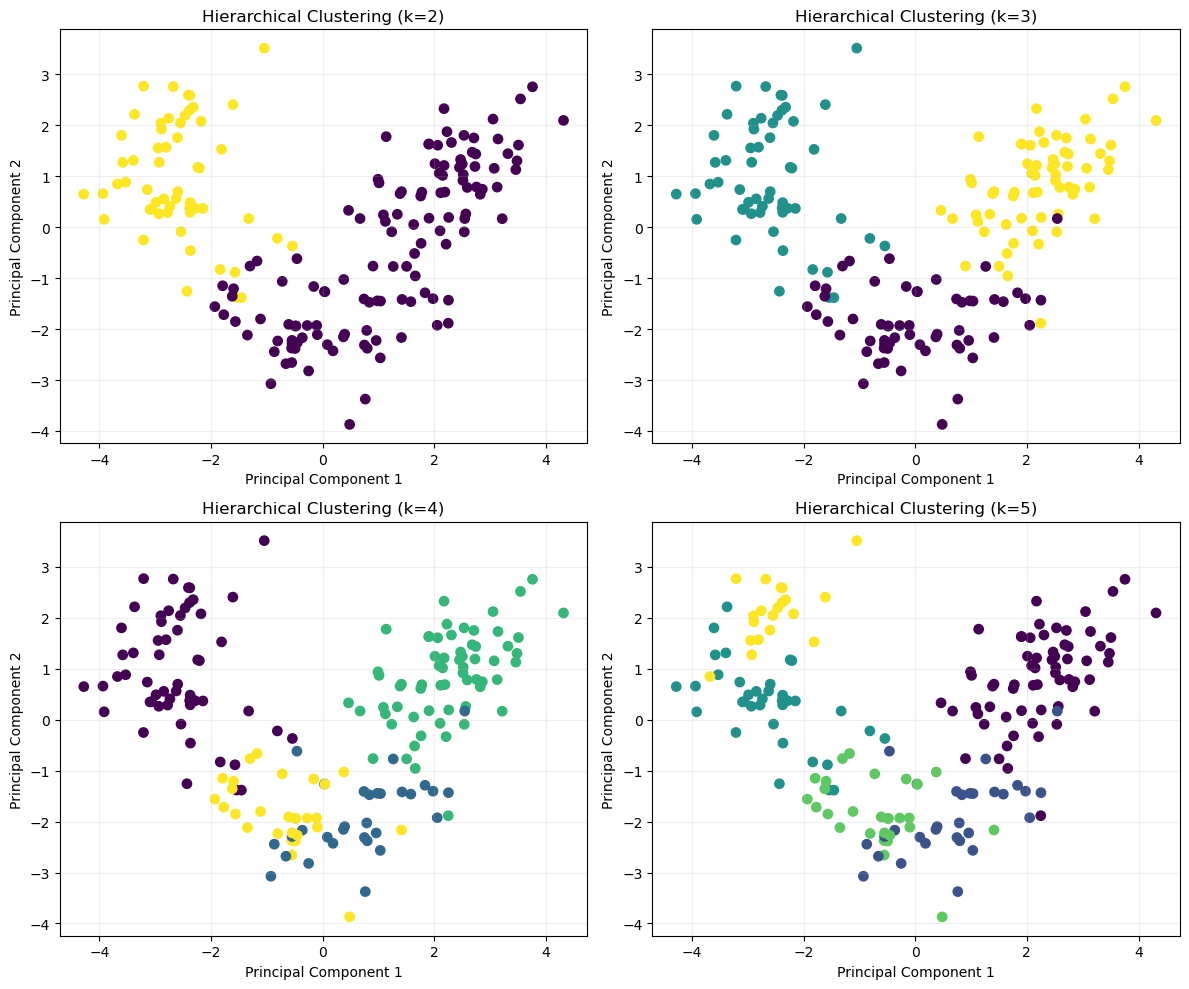

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    labels = hierarchical_labels[k]

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=45
    )

    ax.set_title(f"Hierarchical Clustering (k={k})")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

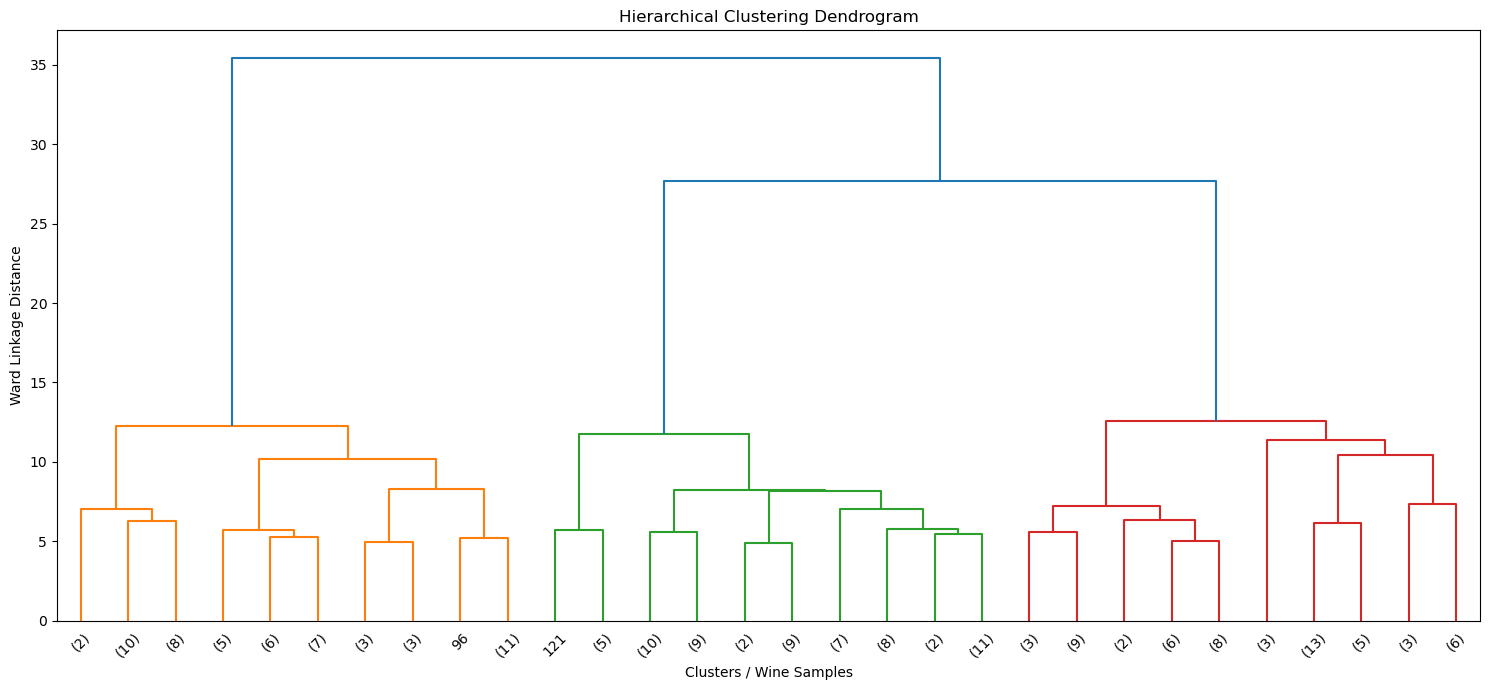

In [21]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(15, 7))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters / Wine Samples")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

### Hierarchical Clustering Observations

I tested the algorithm with 2, 3, 4, and 5 clusters. Among these settings, the highest Silhouette Score was obtained with 3 clusters, at approximately 0.277.

The scatter plots show how the groupings change when the number of clusters increases. The dendrogram shows how smaller groups are gradually combined into larger ones. Branches that merge at higher distances indicate groups that are more different from each other.

Hierarchical Clustering is useful for understanding the structure of the dataset, but the number of clusters must be selected beforehand.

## Step 3: DBSCAN Clustering

DBSCAN is a density-based clustering algorithm that groups data points that are close to each other. Unlike Hierarchical Clustering, DBSCAN does not require the number of clusters to be specified in advance.

I will test different values of eps and min_samples to see how they affect the number of clusters and noise points.

The results will be evaluated using Silhouette Score, Homogeneity Score, and Completeness Score.

In [22]:
dbscan_results = []

for eps in [1.5, 2.0, 2.5, 3.0]:
    for min_samples in [5, 8]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        cluster_mask = labels != -1

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)

        silhouette = np.nan

        if 2 <= n_clusters < np.sum(cluster_mask):
            silhouette = silhouette_score(
                X_scaled[cluster_mask],
                labels[cluster_mask]
            )

        if n_clusters >= 1:
            homogeneity = homogeneity_score(y, labels)
            completeness = completeness_score(y, labels)
        else:
            homogeneity = np.nan
            completeness = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise Points": n_noise,
            "Silhouette": silhouette,
            "Homogeneity": homogeneity,
            "Completeness": completeness
        })

dbscan_df = pd.DataFrame(dbscan_results)

print("DBSCAN Clustering Results:")
display(dbscan_df.round(3))

DBSCAN Clustering Results:


,eps,min_samples,Clusters,Noise Points,Silhouette,Homogeneity,Completeness
0,1.5,5,0,178,NaN,NaN,NaN
1,1.5,8,0,178,NaN,NaN,NaN
2,2.0,5,5,85,0.240,0.362,0.325
3,2.0,8,3,117,0.436,0.390,0.469
4,2.5,5,1,24,NaN,0.058,0.158
5,2.5,8,2,30,0.318,0.484,0.545
6,3.0,5,1,11,NaN,0.031,0.145
7,3.0,8,1,11,NaN,0.031,0.145


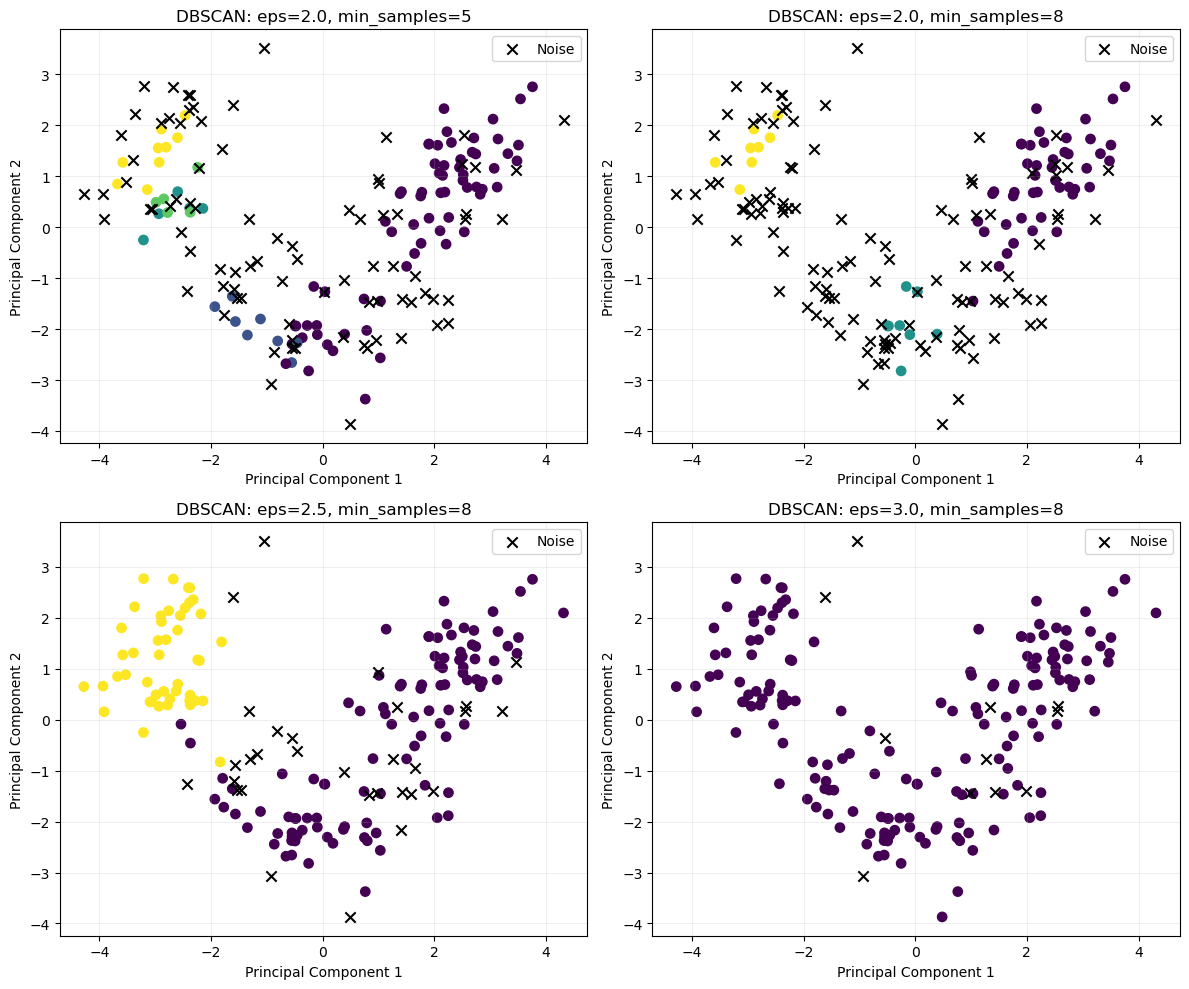

In [23]:
settings = [
    (2.0, 5),
    (2.0, 8),
    (2.5, 8),
    (3.0, 8)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (eps, min_samples) in zip(axes.ravel(), settings):

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    cluster_mask = labels != -1
    noise_mask = labels == -1

    ax.scatter(
        X_pca[cluster_mask, 0],
        X_pca[cluster_mask, 1],
        c=labels[cluster_mask],
        cmap="viridis",
        s=45
    )

    ax.scatter(
        X_pca[noise_mask, 0],
        X_pca[noise_mask, 1],
        c="black",
        marker="x",
        s=55,
        label="Noise"
    )

    ax.set_title(
        f"DBSCAN: eps={eps}, min_samples={min_samples}"
    )

    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

DBSCAN Results
Number of Clusters: 2
Number of Noise Points: 30


,eps,min_samples,Clusters,Noise Points,Silhouette,Homogeneity,Completeness
5,2.5,8,2,30,0.318,0.484,0.545


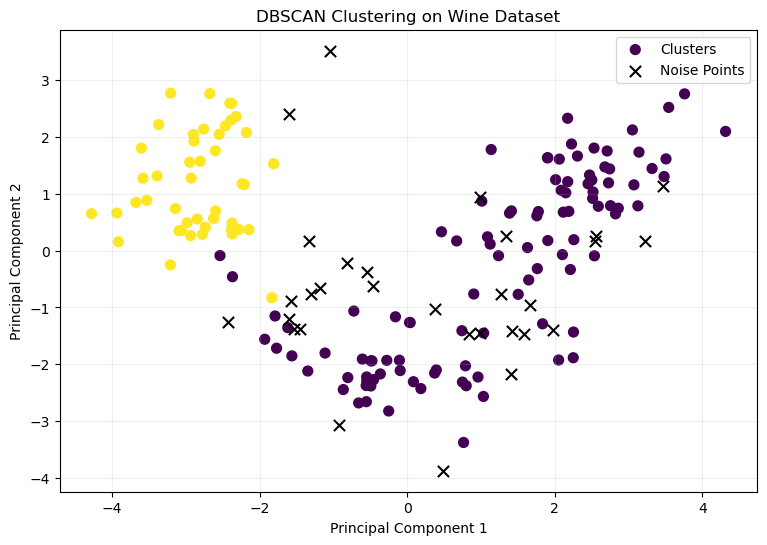

In [24]:
dbscan_model = DBSCAN(
    eps=2.5,
    min_samples=8
)

dbscan_labels = dbscan_model.fit_predict(X_scaled)

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("DBSCAN Results")
print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

selected_result = dbscan_df[
    (dbscan_df["eps"] == 2.5) &
    (dbscan_df["min_samples"] == 8)
]

display(selected_result.round(3))

plt.figure(figsize=(9, 6))

cluster_mask = dbscan_labels != -1
noise_mask = dbscan_labels == -1

plt.scatter(
    X_pca[cluster_mask, 0],
    X_pca[cluster_mask, 1],
    c=dbscan_labels[cluster_mask],
    cmap="viridis",
    s=50,
    label="Clusters"
)

plt.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c="black",
    marker="x",
    s=65,
    label="Noise Points"
)

plt.title("DBSCAN Clustering on Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### DBSCAN Clustering Observations

I tested DBSCAN using different values of eps and min_samples. The results showed that these parameters have a major effect on the number of clusters and noise points.

When eps was 1.5, all 178 samples were marked as noise. When eps increased, more samples were grouped into clusters.

With eps=2.5 and min_samples=8, DBSCAN identified 2 clusters and 30 noise points. The Silhouette Score for the non-noise samples was approximately 0.318.

DBSCAN is useful for identifying unusual data points, but choosing suitable parameter values can be challenging. Some settings resulted in too many noise points, while others combined most of the data into one cluster.

## Step 4: Analysis and Insights

In this section, I will compare Hierarchical Clustering and DBSCAN using the evaluation scores, number of clusters, and clustering visualizations.

I will also discuss how the parameters affected the results and the strengths and weaknesses of each method.

In [25]:
hierarchical_selected = hierarchical_df[
    hierarchical_df["Clusters"] == 3
].iloc[0]

dbscan_selected = dbscan_df[
    (dbscan_df["eps"] == 2.5) &
    (dbscan_df["min_samples"] == 8)
].iloc[0]

comparison = pd.DataFrame({
    "Algorithm": [
        "Hierarchical Clustering",
        "DBSCAN"
    ],
    "Clusters": [
        3,
        dbscan_selected["Clusters"]
    ],
    "Noise Points": [
        0,
        dbscan_selected["Noise Points"]
    ],
    "Silhouette": [
        hierarchical_selected["Silhouette"],
        dbscan_selected["Silhouette"]
    ],
    "Homogeneity": [
        hierarchical_selected["Homogeneity"],
        dbscan_selected["Homogeneity"]
    ],
    "Completeness": [
        hierarchical_selected["Completeness"],
        dbscan_selected["Completeness"]
    ]
})

print("Comparison of Clustering Algorithms:")
display(comparison.round(3))

Comparison of Clustering Algorithms:


,Algorithm,Clusters,Noise Points,Silhouette,Homogeneity,Completeness
0,Hierarchical Clustering,3.0,0.0,0.277,0.790,0.783
1,DBSCAN,2.0,30.0,0.318,0.484,0.545


### Comparison of Hierarchical Clustering and DBSCAN

Both algorithms produced different results on the Wine dataset.

Hierarchical Clustering with 3 clusters achieved a Silhouette Score of approximately 0.277. It also produced relatively high Homogeneity and Completeness Scores, showing that its groups had a reasonable relationship with the actual wine classes.

DBSCAN with eps=2.5 and min_samples=8 identified 2 clusters and 30 noise points. Its Silhouette Score was approximately 0.318 when calculated without noise points. However, this score cannot be directly compared with the Hierarchical result because it was calculated using fewer samples.

Hierarchical Clustering was easier to interpret because I could select the number of clusters and examine the dendrogram. DBSCAN was useful for identifying noise points, but its results changed significantly with different parameter values.

Overall, Hierarchical Clustering provided a more consistent grouping for this dataset, while DBSCAN helped demonstrate how density-based clustering can identify unusual observations.

### Challenges and Decisions

One challenge in this lab was choosing suitable clustering parameters. In Hierarchical Clustering, I tested different numbers of clusters instead of selecting one value immediately.

For DBSCAN, I had to experiment with eps and min_samples because some settings classified almost every sample as noise. I also learned that the Silhouette Score cannot be calculated in every situation, especially when DBSCAN does not find enough clusters.

I used PCA to make the scatter plots easier to understand, while keeping all 13 standardized features for the actual clustering process.

## Conclusion

This lab helped me understand the differences between Hierarchical Clustering and DBSCAN. Both methods can group similar data, but they approach clustering differently.

Hierarchical Clustering builds groups by merging similar samples, while DBSCAN uses density to form clusters and detect noise points.

By testing different parameters and comparing the evaluation metrics, I learned how the choice of clustering algorithm and its settings can affect the final results.